# 05-任务优先级、状态与生命周期管理


## 1. 本篇内容与学习目标

本篇是《FreeRTOS 从入门到实战》十七篇笔记中的第05篇，按两份课程PPT的顺序整理。

| 课程PPT | 原课主题 | 本篇重点 |
|---|---|---|
| `09freeRTOS任务优先级.pptx` | 任务优先级 | 同优先级轮转、高优先级抢占、任务饥饿与阻塞延时 |
| `10freeRTOS任务状态.pptx` | 任务状态 | 四种状态、挂起与恢复、删除和资源回收、按键控制案例 |

承接第04篇的任务创建，本篇要解决的是：任务已经创建，为什么有的任务仍然不执行？怎样让任务暂时停止、继续运行或结束生命周期？

示例沿用课程的单核GD32工程。先观察优先级对执行的影响，再通过任务状态解释这些现象，最后用按键控制红灯任务。代码放在Markdown中供阅读和对照。


## 2. 任务优先级：数字越大，优先级越高

FreeRTOS任务优先级的合法范围为：

```text
0 ～ configMAX_PRIORITIES - 1
```

`configMAX_PRIORITIES` 在工程的 `FreeRTOSConfig.h` 中配置，表示可用的优先级级数。0是最低优先级，空闲任务Idle Task使用这一优先级；应用任务也可以设为0。

创建任务时，`xTaskCreate()` 的第五个参数设置任务优先级。例如，优先级2的Task3高于优先级1的Task1和Task2。

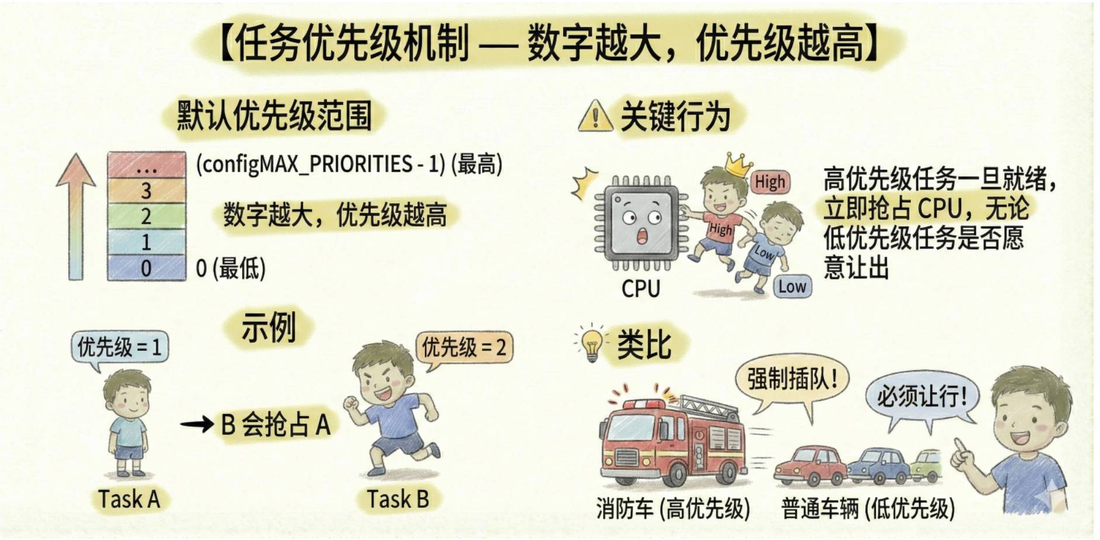

调度器在**可以运行的任务中选择最高优先级任务**。已创建的高优先级任务若处于阻塞或挂起状态，并不会因为数字大就占用CPU。

在课程启用抢占的配置下，更高优先级任务一旦就绪，会触发调度，让它获得CPU。低优先级任务不需要先主动返回。

> 边界补充：课件的“立即抢占”指正常允许切换的条件。临界区、调度器暂停或尚未退出的中断会影响实际切换时机。任务优先级也不能套用中断优先级的数值规则。


## 3. 场景一：相同优先级任务的时间片轮转

课程先创建两个任务，优先级都设为1。Task1打印“1”，Task2打印“2”，观察两个任务能否交替执行。

在工程的 `FreeRTOSConfig.h` 中核对课件列出的三个配置：

```c
#define configUSE_PREEMPTION  1    // 启用抢占式调度（课件标注“默认”）
#define configUSE_TIME_SLICING 1   // 启用时间片轮转
#define configTICK_RATE_HZ    1000 // tick频率1000 Hz，tick间隔1 ms
```

| 配置项 | 对本场景的影响 |
|---|---|
| `configUSE_PREEMPTION == 1` | 允许内核根据调度条件主动切换任务 |
| `configUSE_TIME_SLICING == 1` | 同优先级就绪任务可在tick到来时轮流获得CPU |
| `configTICK_RATE_HZ == 1000` | 每秒1000个tick，提供1 ms的时间基准 |

当Task1和Task2都保持就绪、又没有更高优先级任务占用CPU时，tick触发的时间片轮转让它们轮流执行。课程用串口中“1”和“2”都持续出现来展示这一点。

时间片按执行时间划分，不能据此要求串口必须逐字符严格显示 `121212`。一次打印可能跨越切换点，串口驱动和打印耗时也会影响可见排列。

> 配置核对：在官方FreeRTOS-Kernel V10.5.1中，`configUSE_PREEMPTION` 必须由工程明确配置；`configUSE_TIME_SLICING` 未定义时默认为1。课件的“默认抢占”描述常见示例配置，不应代替检查当前工程。课件写“每1 ms触发一次调度”，更准确地说是每1 ms产生tick，**不代表每个tick都必然切换到不同任务**。任务主动阻塞等操作也能触发调度。

本场景的验证目标是观察同优先级任务共享CPU。若关闭时间片轮转，也不能推导为“同优先级任务永远不切换”，任务主动阻塞或让出时仍可能发生切换。


## 4. 场景二：高优先级任务让低优先级任务“饿死”

课程随后增加Task3，将其优先级设为2，Task1和Task2仍为1。让Task3持续工作、不进入阻塞，观察串口变化。

| 任务 | 优先级 | 场景中的状态与表现 |
|---|---|---|
| Task1 | 1 | 可以运行，但长期得不到CPU |
| Task2 | 1 | 可以运行，但长期得不到CPU |
| Task3 | 2 | 持续处于运行或就绪状态，占据最高就绪优先级 |

课程预期现象是Task3持续执行，Task1和Task2不再执行。这称为任务饥饿：低优先级任务需要执行，却一直没有机会。

根本原因是Task3始终可以运行。时间片轮转只在当前最高就绪优先级内分配时间，不能把优先级2任务的时间片自动分给优先级1任务。

处理方法是在Task3完成本次工作后调用带有正延时的 `vTaskDelay()`，使它暂时退出就绪集合。此时调度器才能选择优先级1的任务。

> 必要补充：仅调用 `taskYIELD()` 或 `vTaskDelay(0)` 并不能解决这里的饥饿。它们会请求重新调度，但Task3仍保持就绪，仍是最高优先级任务。普通忙等延时同样不会把Task3移出就绪集合。

这个场景要区分“任务被阻塞”和“任务得不到CPU”：前者在等待时间或事件，后者可能仍然就绪，只是被更高优先级任务压住。


## 5. vTaskDelay：在等待期间释放CPU

课件对比普通 `delay()` 与FreeRTOS延时，用来解释为什么把裸机延时直接搬进任务会影响调度。

| 延时方式 | 等待期间的任务行为 | 对其他任务的影响 |
|---|---|---|
| 普通 `delay()`，内部使用 `while` 忙等 | 继续执行循环，没有主动进入阻塞 | 同级或更高优先级任务可能抢占它，但低优先级任务可能持续被压住 |
| `vTaskDelay(pdMS_TO_TICKS(500))` | 当换算结果大于0时，进入阻塞状态等待指定tick数 | 调度器可运行其他就绪任务 |

课程给出的500 ms写法是：

```c
vTaskDelay(pdMS_TO_TICKS(500));
```

`vTaskDelay()` 的参数单位是tick。`pdMS_TO_TICKS()` 按当前tick频率把毫秒换算成tick，避免把“500 tick”和“500 ms”混为一谈。

其工作过程是：

1. 当前任务调用带有正tick数的 `vTaskDelay()`。
2. 内核将该任务移出就绪集合，记录唤醒时间。
3. 调度器选择其他就绪任务运行；若没有应用任务就绪，Idle Task可以运行。
4. 延时到期，任务回到就绪状态。
5. 调度器根据优先级和当前可运行任务决定何时再次执行它。

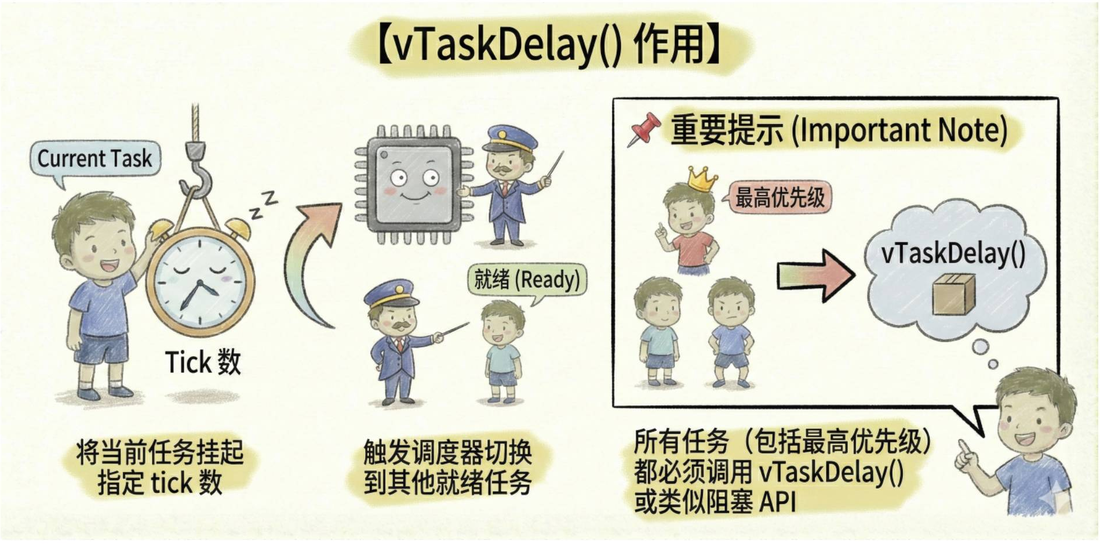

> 术语核对：课件表格和图中把延时称为“挂起任务”，这里应理解为**阻塞（Blocked）**。显式挂起（Suspended）由 `vTaskSuspend()` 实现，没有延时到期自动恢复这一行为。

`vTaskDelay()` 是相对延时，到期表示任务具备再次运行的条件。实际恢复执行还可能受更高优先级任务影响，不能用它承诺精确的墙钟周期。换算后的tick数为0时，也不会产生正时长的阻塞。

> 范围补充：课件标题写“正确释放CPU的唯一方式”，但同一课的图也写了“或类似阻塞API”。队列、信号量等等待也能让任务阻塞。本课重点是在LED和打印循环中用 `vTaskDelay()` 替代长时间忙等，而不是要求每个任务必须只使用这一种API。


## 6. 裸机轮询与FreeRTOS调度的差异

课件用裸机主循环与启用抢占的FreeRTOS工程作比较，重点是后一个工作是否必须等前一个工作主动结束。

| 维度 | 课程中的裸机轮询 | 本课FreeRTOS工程 |
|---|---|---|
| 执行安排 | 主循环依次调用处理函数，函数返回后才能继续后续工作 | 内核根据任务状态、优先级及时间片安排执行 |
| 时间控制 | 一个处理函数过长，会拉长整个轮询周期 | 可优先运行紧急任务，并让等待任务进入阻塞 |
| 多项工作推进 | 各处理函数按调用顺序推进 | 多个任务交替推进，各自保留执行上下文 |
| 某项工作无法继续 | 若轮询函数卡在忙等，后续函数无法执行 | 正常阻塞的任务退出就绪集合，其他就绪任务仍可执行 |

这解释了为什么红灯、绿灯与串口打印可以有不同的等待时间。一个任务在等，另一个任务可以继续做事。

> 边界补充：课件将RTOS称为“真并发（宏观并行）”。在本课单核芯片上，任一时刻仍只有一个任务在CPU上运行，多项工作通过切换并发推进。课件的“任务卡死，其他照常运行”也有前提：高优先级忙循环、长时间关中断或破坏共享资源都可能影响整个系统，普通FreeRTOS不会自动提供完整故障隔离。

裸机本身也能使用中断与非阻塞状态机，FreeRTOS也支持其他调度配置。本表仅比较课件中的轮询写法与当前抢占配置。


## 7. 优先级安排与任务循环的工程要求

优先级课件最后强调：高优先级任务应尽快完成当前工作，然后进入合适的等待，避免长期压住其他任务。

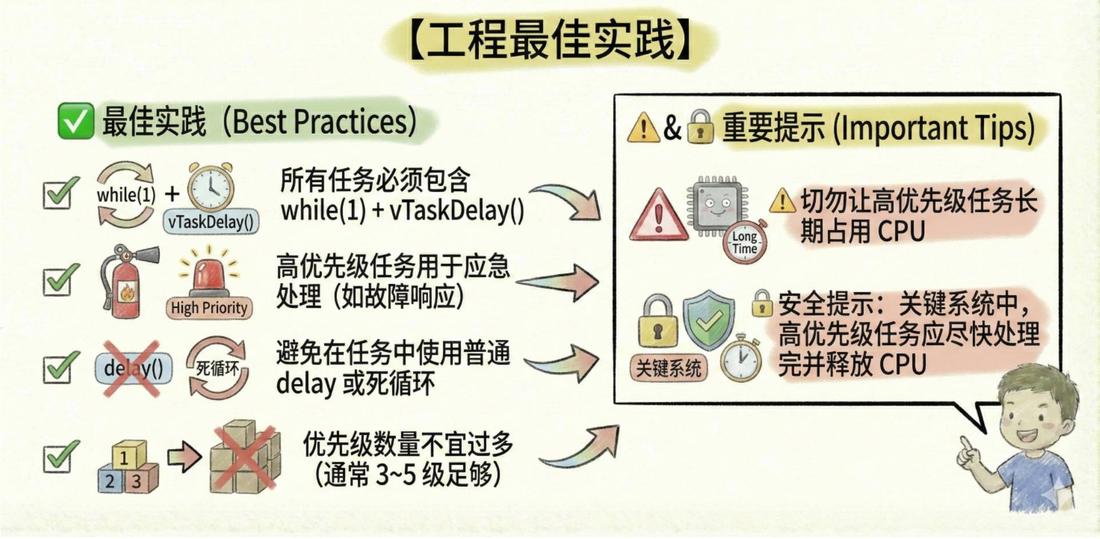

课程建议保留如下：

- 持续工作的LED、打印任务使用循环，每轮完成工作后调用 `vTaskDelay()`。
- 高优先级用于响应要求较高的工作，例如故障响应；应控制每次连续执行的时长。
- 周期性等待避免使用长时间普通忙等延时。
- 优先级级数不宜无目的地增加，课件建议简单工程通常3～5级足够。
- 所有优先级的任务都要考虑等待与CPU使用，不能认为最高优先级任务可以无限占用CPU。

> 范围补充：图中“所有任务必须包含 `while(1) + vTaskDelay()`”是本课持续运行案例的写法。等待事件的任务可以使用其他阻塞API，有限工作任务也可以在完成后删除自身。3～5级是课程建议，不是内核限制。这里的“避免死循环”指避免无休止忙运行，任务入口本身采用无限循环并不矛盾。

到此，优先级课的关键现象是：同级就绪任务可轮转，更高优先级就绪任务优先执行，高优先级任务适当阻塞后低优先级任务才有机会运行。接下来用状态描述这些变化。


## 8. 任务的四种核心状态

任务状态课件区分Ready、Running、Blocked和Suspended四种状态。

| 状态 | 中文 | 含义 | 能否被调度执行 |
|---|---|---|---|
| Ready | 就绪 | 具备运行条件，正在等CPU | 能，按优先级参与选择 |
| Running | 运行 | 当前正在CPU上执行 | 已在执行；本课单核同时只有一个运行任务 |
| Blocked | 阻塞 | 等待时间到期或事件满足 | 等待期间不能 |
| Suspended | 挂起 | 被显式暂停，等待恢复操作 | 挂起期间不能 |

阻塞和挂起都不占用任务执行时间，但解除条件不同。

| 比较点 | 阻塞 | 显式挂起 |
|---|---|---|
| 进入方式 | 调用带等待条件的API，例如正延时的 `vTaskDelay()` | 调用 `vTaskSuspend()` |
| 等待对象 | 时间或事件，例如队列数据 | 显式恢复操作 |
| 回到就绪的条件 | 延时到期、事件满足或相应等待结束 | 对有效任务句柄调用 `vTaskResume()` 等恢复接口 |
| 任务内存 | 任务仍存在，栈与控制块仍保留 | 任务仍存在，栈与控制块仍保留 |

> 术语补充：课件把阻塞描述为“到期自动恢复”，时间等待适用这一说法，事件等待也可能因事件满足而解除。回到就绪不等于立刻运行。这里的挂起专指显式暂停，不把内部链表如何保存无限期等待任务混进这四种状态的入门定义。


## 9. 四种状态之间如何转换

原课用以下状态转换图展示任务从创建到等待、暂停和继续执行的过程。

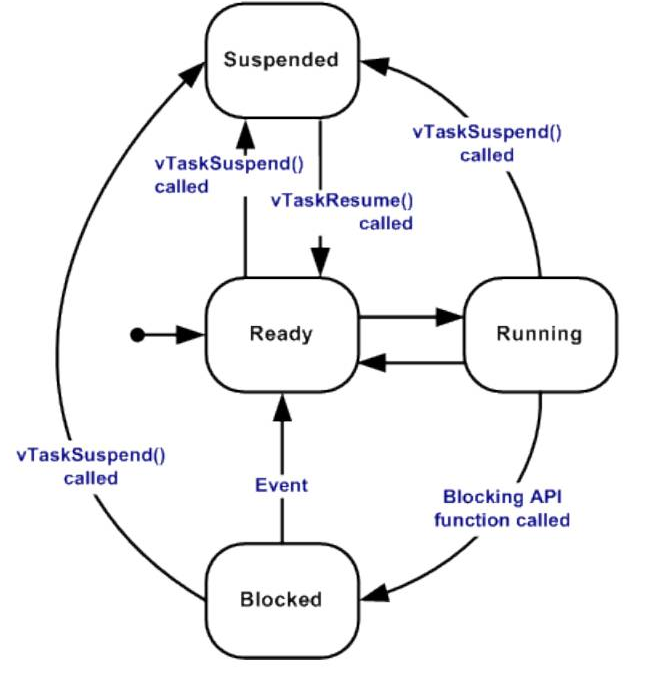

按图中的箭头理解：

| 转换 | 触发条件 |
|---|---|
| 创建后进入Ready | 任务创建成功，具备被调度条件 |
| Ready进入Running | 调度器选中该任务 |
| Running回到Ready | 发生抢占、时间片切换等调度变化，任务仍能运行 |
| Running进入Blocked | 调用需要等待的阻塞API |
| Blocked回到Ready | 等待的时间或事件条件满足 |
| Ready、Running或Blocked进入Suspended | 对该任务调用 `vTaskSuspend()` |
| Suspended回到Ready | 通过有效句柄恢复该任务 |

在课程LED任务里，翻转LED后调用正延时的 `vTaskDelay()`，就是Running进入Blocked；等待结束后回到Ready，再按调度结果运行下一轮。

若按键任务调用 `vTaskSuspend(xTask1Handle)`，红灯任务转入Suspended。时间继续流逝不会使它重新闪烁，必须执行恢复操作。

删除会把任务移出内核管理，其后不能再按这张图恢复到Ready。要重新执行，只能重新创建一个任务实例。


## 10. 挂起与恢复：句柄和NULL的含义

课程给出两个任务控制接口：

```c
// 挂起指定任务
void vTaskSuspend(TaskHandle_t xTaskToSuspend);

// 恢复指定任务
void vTaskResume(TaskHandle_t xTaskToResume);
```

使用前，核对实际工程的 `FreeRTOSConfig.h`。以下为根据参考内核接口补充的启用条件，不是课件新增的创建流程：

```c
#define INCLUDE_vTaskSuspend 1
```

这个宏同时控制挂起和任务上下文恢复接口。任务源文件应在 `FreeRTOS.h` 之后包含 `task.h`，并使用创建时保存的有效任务句柄。

| 调用 | 实际含义 |
|---|---|
| `vTaskSuspend(xTask1Handle)` | 挂起句柄指向的红灯任务 |
| `vTaskSuspend(NULL)` | 挂起调用该API的当前任务 |
| `vTaskResume(xTask1Handle)` | 让指定的显式挂起任务重新就绪 |
| `vTaskResume(NULL)` | 不能作为恢复当前任务的有效写法 |

> 课件纠正：第6页把NULL统一解释为“挂起/恢复当前任务”，恢复部分不准确。官方V10.5.1的 `vTaskResume()` 要求非NULL句柄，并包含相应断言。一个已经挂起的任务无法执行自身代码来自行恢复，必须由其他执行路径恢复它。

挂起适用于按键暂停采集，或故障时临时停止非关键任务。它保留执行上下文和任务内存，恢复后继续原来的执行流程，不会从任务入口重新开始。

> 必要补充：挂起不是嵌套计数，多次 `vTaskSuspend()` 不要求同次数的恢复。若显式挂起一个原本处于阻塞状态的任务，恢复使它回到就绪，不能把它当成“冻结并继续原来的剩余延时”。本课验证只要求暂停和继续闪烁。


## 11. 删除任务与资源回收

课程给出的删除接口为：

```c
// 删除任务，传NULL表示删除当前任务
void vTaskDelete(TaskHandle_t xTaskToDelete);
```

使用前，在 `FreeRTOSConfig.h` 核对接口启用条件：

```c
#define INCLUDE_vTaskDelete 1
```

删除后，任务从就绪、阻塞、挂起及相关事件等待结构中移除，不能再执行，也不能通过 `vTaskResume()` 恢复。

课件强调删除后将应用保存的句柄置空，原示例如下。这里以**一个任务删除另一个任务**为前提：

```c
vTaskDelete(xTaskHandle);
xTaskHandle = NULL; // 避免继续使用已失效句柄
```

若删除自身，`vTaskDelete(NULL)` 之后的代码不会继续执行，不能把必要的清理操作安排在它后面。

### 删除与回收的时机

课件写“删除不等于立即释放内存，实际回收由Idle Task异步完成”。这个提醒对任务自删很重要，但不能统一套到所有删除场景。

| 情况 | 官方V10.5.1单核实现中的处理 |
|---|---|
| 任务删除自身 | 先停止调度该任务，进入待清理结构，再由Idle Task清理内核拥有的任务资源 |
| 一个任务删除另一个任务 | 删除调用内直接执行任务控制块清理，动态分配的任务栈和控制块通过对应释放接口回收 |
| 使用用户提供的静态栈和静态控制块 | 这些内存仍归应用所有，内核不会把它们当作动态内存释放 |

因此不能根据KEY3按键案例推导为“内存一定等到Idle Task运行后才释放”：该案例由按键任务删除红灯任务，属于删除其他任务。

> 版本说明：上述回收时机经官方FreeRTOS-Kernel V10.5.1的 `tasks.c` 核对，仅用于澄清课件边界，尚未确认课程配套源码的具体版本。动态回收还需要工程采用支持释放的内存管理实现。

任务函数自己申请的数据缓冲区，以及它持有的外设或同步资源，需要应用在删除前妥善处理。`vTaskDelete()` 不会自动释放业务代码申请的所有资源。

句柄置空只修改这一份变量，其他副本同样会失效。后续操作还要先判断句柄是否有效：将NULL传入 `vTaskDelete()` 会删除**调用者自身**，将NULL传入 `vTaskSuspend()` 会挂起调用者。


## 12. 按键控制多任务：原课任务规划

任务状态课件的实战案例安排四个任务。

| 任务 | 工作内容 | 课件时间参数 |
|---|---|---|
| Task1 | 红灯闪烁 | 250 ms |
| Task2 | 绿灯闪烁 | 1000 ms |
| Task3 | 串口打印“3” | 1 s一次 |
| Task4 | 按键扫描 | 10 ms周期 |

前三个任务各自工作和等待，Task4接收按键操作，控制Task1的生命周期。创建红灯任务时需要保存 `xTask1Handle`，其他控制接口依靠这一句柄找到任务。

课件没有在这两份PPT中给出完整四任务源码、具体优先级数值、按键引脚或扫描函数名称。实现时沿用既有工程的板级接口和初始化，不能仅凭此表套用一份未经确认的硬件代码。

第04篇已使用 `bsp_leds_toggle()` 说明LED翻转。如果循环每次翻转后等待250 ms，250 ms表示两次翻转之间的等待量，完整亮灭周期约为500 ms；绿灯相应约为2000 ms。任务工作耗时和调度也会影响实际间隔。课件的“250 ms/1000 ms闪烁”参数保留，调试时需要区分翻转间隔和完整周期。

本例按键功能固定为：

| 按键 | 课件调用 | 目标行为 |
|---|---|---|
| KEY1 | `vTaskSuspend(xTask1Handle)` | 暂停红灯任务，红灯停止翻转 |
| KEY2 | `vTaskResume(xTask1Handle)` | 恢复红灯任务，继续闪烁 |
| KEY3 | `vTaskDelete(xTask1Handle); xTask1Handle = NULL;` | 删除红灯任务，本次实例永久停止 |

> 现象核对：课件KEY1写“红灯常亮”。挂起只停止任务执行，不会主动把GPIO改成亮；若只调用挂起，红灯可能常亮，也可能常灭，取决于停下时的电平。验证目标应是“停止闪烁”。要保证常亮还需额外设置LED输出，但这两份课件没有给出该操作。


## 13. 按键分支中的控制调用

控制调用放在Task4识别到对应按键事件的分支内。以下片段根据课件调用补上句柄判断，不是课程完整源码；按键扫描与消抖沿用实际工程。

### KEY1：暂停红灯任务

```c
// 放在KEY1按下事件的处理分支中
if (xTask1Handle != NULL)
{
    vTaskSuspend(xTask1Handle);
}
```

任务被挂起后，红灯保持停止时的电平。任务的栈、控制块及句柄仍存在，所以后续可以恢复。

### KEY2：继续红灯任务

```c
// 放在KEY2按下事件的处理分支中
if (xTask1Handle != NULL)
{
    vTaskResume(xTask1Handle);
}
```

KEY2通过有效句柄把显式挂起的任务恢复到就绪。红灯任务获得CPU后继续执行，不能保证恢复后等完整250 ms才出现第一次翻转。

### KEY3：结束红灯任务

```c
// 放在KEY3按下事件的处理分支中
if (xTask1Handle != NULL)
{
    vTaskDelete(xTask1Handle);
    xTask1Handle = NULL;
}
```

第一次删除后句柄变为NULL，再次按KEY3不会重复删除，更不会误把按键任务自身删除。删除后再按KEY1或KEY2，也不会把NULL交给控制接口。

Task4每轮扫描后应使用课件的10 ms等待思路。接口调用可写为：

```c
vTaskDelay(pdMS_TO_TICKS(10));
```

这是完成本轮处理后的相对延时；扫描与处理耗时也计入两次扫描之间的间隔。不要用忙等实现这一等待。使用 `vTaskDelay()` 还需核对 `INCLUDE_vTaskDelay == 1`。

> 使用条件：这些句柄检查以本课由按键任务统一控制Task1为前提，不能单靠一次非NULL判断保证多个任务同时删除、替换句柄时的安全。本例也不在中断里直接执行挂起或删除。


## 14. 开发板上的验证顺序与预期现象

在已完成移植的课程工程中核对宏和任务创建结果，编译后下载到实际开发板，再观察LED和串口。本节记录应验证的现象，**未进行开发板编译、下载或运行**。

先核对基本条件：

- `configUSE_PREEMPTION`、`configUSE_TIME_SLICING` 与时间片场景一致。
- `configTICK_RATE_HZ` 和 `pdMS_TO_TICKS()` 换算匹配。
- `INCLUDE_vTaskDelay`、`INCLUDE_vTaskSuspend`、`INCLUDE_vTaskDelete` 已启用。
- 四个任务创建成功，红灯任务句柄正确保存；硬件初始化在使用外设前完成。
- 各持续循环在工作后有合适等待，按键扫描能产生明确的按下事件。

随后按以下顺序观察：

| 步骤 | 操作 | 预期现象与含义 |
|---|---|---|
| 1 | 启动四任务案例 | 红灯、绿灯各自闪烁，串口约每1 s打印一次“3”，按键任务持续扫描 |
| 2 | 按KEY1 | 红灯停止翻转，绿灯和打印继续，说明Task1已显式挂起 |
| 3 | 等待超过原红灯延时 | 红灯仍停止翻转，说明挂起不会因时间到期自动恢复 |
| 4 | 按KEY2 | 红灯继续闪烁，说明有效句柄可恢复挂起任务 |
| 5 | 按KEY3 | 红灯停止翻转，`xTask1Handle` 被置为NULL，Task1实例已删除 |
| 6 | 再按KEY2或KEY3 | 红灯不再恢复，按键任务和其他任务继续运行，句柄判断阻止无效操作 |

“永久停止”针对已经删除的任务实例。重启工程或重新创建Task1可以产生新的实例，这不属于 `vTaskResume()` 的恢复行为。

若所有任务同时失去响应，优先检查是否把NULL传给了挂起或删除接口，是否出现更高优先级忙循环，再核对移植配置；不能仅根据红灯不闪就断定它被挂起。若KEY3后再按键导致系统异常，应首先检查是否继续使用失效句柄。


## 15. 生命周期控制的工程边界

状态课件最后强调临时暂停和永久结束的区别，并提醒保护内核任务。

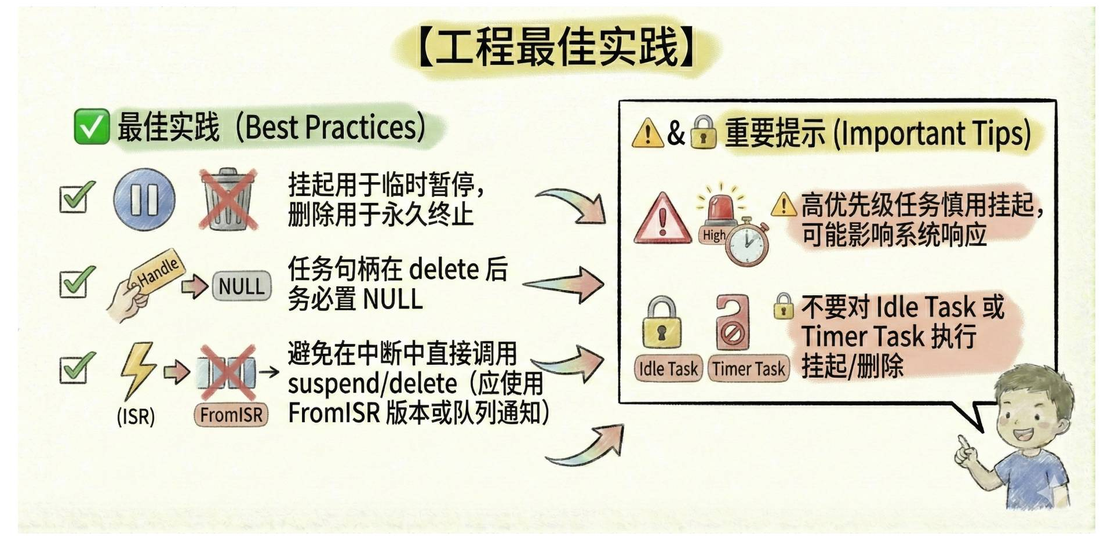

按本课案例应用这些建议：

| 场景 | 对应做法与边界 |
|---|---|
| 临时暂停业务 | 挂起后保留任务内存，用有效句柄恢复 |
| 结束当前任务实例 | 删除前处理业务资源，删除其他任务后将所保存句柄置空 |
| 高优先级任务需要暂停 | 先确认暂停不会切断关键响应，不能机械地挂起重要任务 |
| Idle Task | 不对它执行挂起或删除；任务自删的延后清理需要它获得运行机会 |
| Timer Task | 启用软件定时器时，不挂起或删除其服务任务，否则定时器处理受到影响 |
| 中断触发任务控制 | 使用对应的中断安全通信接口，让任务上下文处理暂停或删除请求 |

> 接口核对：课件图中写“suspend/delete应使用FromISR版本或队列通知”。官方V10.5.1没有 `vTaskSuspendFromISR()` 或 `vTaskDeleteFromISR()`，不能自行给函数加后缀。该版本有 `xTaskResumeFromISR()` 用于从中断恢复任务；挂起和删除请求应交给任务上下文处理。中断可通过适用的队列或任务通知FromISR接口传递请求，本课不展开后续通信机制实现。

课件总结的四种核心状态仍是Ready、Running、Blocked和Suspended。正确区分等待、暂停和删除，才能判断一个“不执行”的任务究竟需要等待条件、恢复操作，还是已经结束。

资料说明：两份PPT共25页均已读取，教学内容按原课顺序整理，省略品牌结束页。接口边界补充参考 [FreeRTOS-Kernel V10.5.1](https://github.com/FreeRTOS/FreeRTOS-Kernel/tree/V10.5.1)，未把该版本视为已确认的课程源码版本，也未以示意片段替代完整课程工程。
